# Mejora del modelo: variables de texto, geografía y renta

El análisis por segmentos del notebook `02_modelado` mostró que la principal limitación del modelo
es la **regresión hacia la media**: sobrestima las viviendas más baratas e infravalora las más caras.
Para atacarla se añaden tres grupos de variables (`src/variables_extra.py`):

| Grupo | Variables | Fuente |
|---|---|---|
| **texto** | 14 indicadores: vistas al mar, primera línea, playa, lujo, piscina desbordante, golf, spa, ático, a estrenar, reformado, a reformar, ocupada, cueva, inversión | título y descripción del anuncio |
| **geo** | distancia a la costa y a la capital de provincia | coordenadas + línea de costa (Natural Earth) |
| **renta** | renta neta media por persona del municipio (2024) | INE, Atlas de Distribución de Renta de los Hogares |

Los términos de texto se eligieron analizando los residuos fuera de muestra del modelo base
**solo en el conjunto de entrenamiento**; el de prueba no interviene en ninguna decisión.

Para reproducir:

```bash
python src/modelado.py --pruebas 40 --grupos texto geo renta
python src/ablacion_variables.py --grupos texto geo renta
```

Contenido:

1. Modelo base frente a modelo ampliado.
2. Aportación de cada grupo de variables (ablación).
3. Efecto sobre los extremos de precio y los segmentos.
4. Efecto de las variables de texto.
5. Explicabilidad del modelo ampliado (SHAP).
6. Conclusiones.

Las figuras se guardan en `doc/figuras/mejora/`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import shap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from preprocesado import preparar  # noqa: E402
import variables_extra  # noqa: E402

RES = RAIZ / "data" / "procesado" / "resultados"
GRUPOS = ("texto", "geo", "renta")
RES_AMP = RES / "_".join(GRUPOS)
FIGURAS = RAIZ / "doc" / "figuras" / "mejora"
FIGURAS.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, REJILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})
NOMBRES = {"lineal": "Regresión lineal", "random_forest": "Random Forest", "xgboost": "XGBoost",
           "lightgbm": "LightGBM", "catboost": "CatBoost"}

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")
    plt.show()

res_base = pd.read_csv(RES / "resultados_modelos.csv")
res_amp = pd.read_csv(RES_AMP / "resultados_modelos.csv")
pred_base = pd.read_csv(RES / "predicciones_prueba.csv", dtype={"id_anuncio": str})
pred_amp = pd.read_csv(RES_AMP / "predicciones_prueba.csv", dtype={"id_anuncio": str})
assert (pred_base["id_anuncio"].values == pred_amp["id_anuncio"].values).all()  # mismo conjunto de prueba
MEJOR_BASE = res_base.sort_values("CV_RMSE_log").iloc[0]["modelo"]
MEJOR = res_amp.sort_values("CV_RMSE_log").iloc[0]["modelo"]
print("Mejor modelo base:", NOMBRES[MEJOR_BASE], "| mejor modelo ampliado:", NOMBRES[MEJOR])

Mejor modelo base: LightGBM | mejor modelo ampliado: LightGBM


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Modelo base frente a modelo ampliado

Cada modelo se vuelve a ajustar con Optuna (40 pruebas) con las variables nuevas, con el mismo
procedimiento, las mismas particiones de validación cruzada y el mismo conjunto de prueba.

In [2]:
cols = {"CV_RMSE_log": "RMSE log (CV)", "test_R2_log": "R² log", "test_MdAPE_pct": "MdAPE %",
        "test_MAPE_pct": "MAPE %", "test_MAE_eur": "MAE €"}
comp = pd.concat({"base": res_base.set_index("modelo")[list(cols)],
                  "ampliado": res_amp.set_index("modelo")[list(cols)]}, axis=1)
comp = comp.rename(columns=cols, level=1).rename(index=NOMBRES)
comp = comp.reindex(comp[("ampliado", "RMSE log (CV)")].sort_values().index)
for c in cols.values():
    comp[("cambio", c)] = comp[("ampliado", c)] - comp[("base", c)]
comp = comp[[(g, c) for c in cols.values() for g in ("base", "ampliado", "cambio")]]
comp.round(4)

,base,ampliado,cambio,base,ampliado,cambio,base,ampliado,cambio,base,ampliado,cambio,base,ampliado,cambio
,RMSE log (CV),RMSE log (CV),RMSE log (CV),R² log,R² log,R² log,MdAPE %,MdAPE %,MdAPE %,MAPE %,MAPE %,MAPE %,MAE €,MAE €,MAE €
modelo,,,,,,,,,,,,,,,
LightGBM,0.3053,0.2888,-0.0165,0.8518,0.8632,0.0115,16.3266,15.4563,-0.8703,22.3505,21.0993,-1.2512,79520.1961,76081.3053,-3438.8909
XGBoost,0.3053,0.2890,-0.0163,0.8505,0.8613,0.0108,16.2109,14.5915,-1.6195,22.3376,20.9722,-1.3653,79675.4080,75143.8980,-4531.5100
CatBoost,0.3082,0.2891,-0.0191,0.8447,0.8618,0.0171,17.7548,15.7479,-2.0069,23.1105,21.4136,-1.6969,83579.3106,77316.2457,-6263.0649
Random Forest,0.3255,0.3095,-0.0160,0.8263,0.8402,0.0138,17.7563,16.3620,-1.3942,24.3215,23.1058,-1.2157,85686.8097,82453.3235,-3233.4863
Regresión lineal,0.3836,0.3584,-0.0251,0.7607,0.7876,0.0269,23.2079,21.2664,-1.9416,30.4638,28.3885,-2.0753,104679.7588,98052.6062,-6627.1526


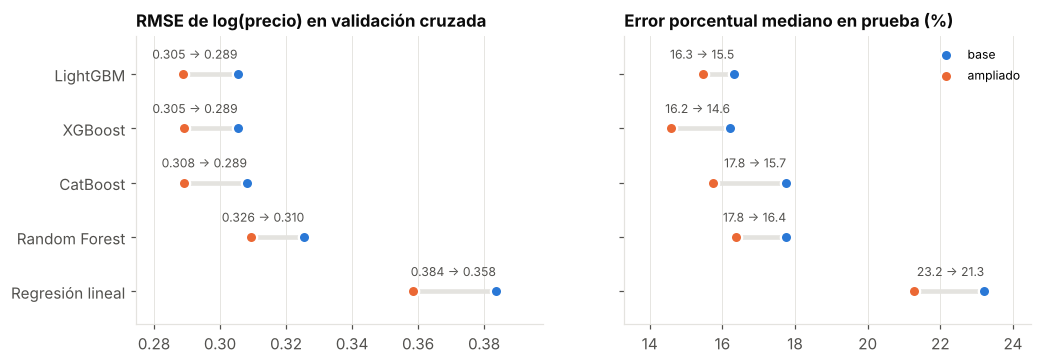

In [3]:
orden = res_amp.set_index("modelo").sort_values("CV_RMSE_log", ascending=False).index
b = res_base.set_index("modelo").loc[orden]
a = res_amp.set_index("modelo").loc[orden]
y = np.arange(len(orden))
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4), sharey=True)
for eje, col, titulo, fmt in [(ax[0], "CV_RMSE_log", "RMSE de log(precio) en validación cruzada", "{:.3f}"),
                              (ax[1], "test_MdAPE_pct", "Error porcentual mediano en prueba (%)", "{:.1f}")]:
    eje.hlines(y, a[col], b[col], color=REJILLA, linewidth=3, zorder=1)
    eje.scatter(b[col], y, color=AZUL, s=55, zorder=3, edgecolor="white", linewidth=1.5, label="base")
    eje.scatter(a[col], y, color=NARANJA, s=55, zorder=3, edgecolor="white", linewidth=1.5, label="ampliado")
    for yi, (vb, va) in enumerate(zip(b[col], a[col])):
        eje.text(max(vb, va), yi + 0.28, f"{fmt.format(vb)} → {fmt.format(va)}", fontsize=8, color=TINTA_2,
                 ha="right")
    eje.set(title=titulo); eje.grid(axis="y", visible=False)
    eje.margins(x=0.15)
ax[0].set_yticks(y, [NOMBRES[m] for m in orden]); ax[0].set_ylim(-0.6, len(orden) - 0.3)
ax[1].legend(loc="upper right", fontsize=8)
guardar(fig, "01_base_vs_ampliado")

**Todos los modelos mejoran con las variables nuevas**, y en una magnitud muy superior a la variabilidad entre particiones. En el mejor modelo, LightGBM:

- el RMSE de log(precio) en validación cruzada baja de 0,305 a 0,289 (−5,4 %);
- el R² en logaritmo sube de 0,852 a 0,863;
- la MdAPE en prueba baja de 16,3 % a 15,5 %;
- el MAE baja de 79.520 € a 76.081 € (−4,3 %).

La regresión lineal es la que más gana. Las distancias recogen relaciones que antes solo podían aproximar los árboles a partir de latitud y longitud.

Los tres modelos de *boosting* quedan prácticamente empatados en validación cruzada (0,2888–0,2891). Que XGBoost obtenga la menor MdAPE en prueba (14,6 %) no justifica cambiar de modelo: la selección se hace por validación cruzada, como se fijó antes de ver el conjunto de prueba, y LightGBM sigue siendo el elegido.

## 2. Aportación de cada grupo de variables (ablación)

Con los hiperparámetros del mejor modelo ampliado fijos, se entrena el modelo con distintas
combinaciones de grupos: cada grupo añadido al modelo base y cada grupo retirado del modelo completo
(su aportación **marginal**). La decisión se toma sobre la validación cruzada; el conjunto de
prueba, de 1.368 viviendas, tiene más ruido para diferencias pequeñas.

In [4]:
ab = pd.read_csv(RES / "ablacion_variables.csv").set_index("variante")
ab[["n_variables", "CV_RMSE_log", "CV_RMSE_log_desv", "test_MdAPE_pct", "test_MAE_eur", "test_R2_log",
    "sesgo_Q1_pct", "sesgo_Q5_pct"]].round(4)

,n_variables,CV_RMSE_log,CV_RMSE_log_desv,test_MdAPE_pct,test_MAE_eur,test_R2_log,sesgo_Q1_pct,sesgo_Q5_pct
variante,,,,,,,,
base,62,0.3065,0.0075,16.7450,80444.4331,0.8495,15.9000,-14.1475
base + texto,76,0.2971,0.0066,16.0353,78811.3669,0.8561,14.5891,-13.9758
base + geo,64,0.2962,0.0091,15.2477,77640.7189,0.8592,12.5139,-12.6543
base + renta,63,0.3065,0.0090,16.4592,79957.2318,0.8514,15.9013,-12.7323
todas,79,0.2888,0.0056,15.4563,76081.3053,0.8632,13.3347,-13.2027
todas - texto,65,0.2976,0.0081,14.9416,77655.0337,0.8592,13.5856,-12.1111
todas - geo,77,0.2970,0.0062,16.0764,78685.0978,0.8557,15.3234,-14.2090
todas - renta,78,0.2887,0.0066,15.3369,76219.3419,0.8640,11.4980,-13.3808


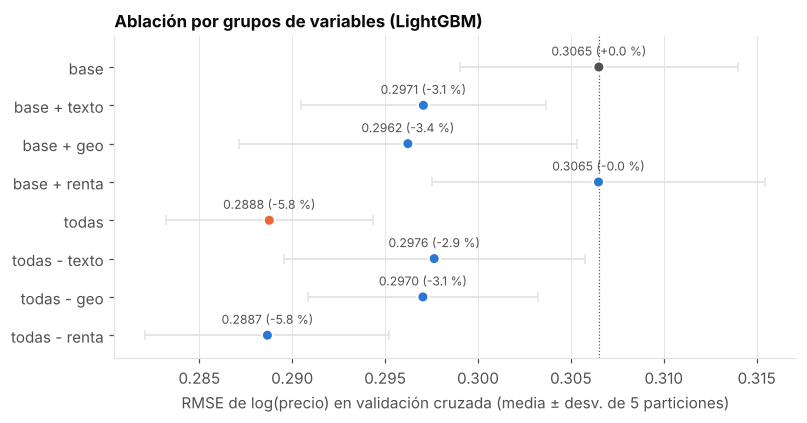

In [5]:
t = ab.iloc[::-1]
y = np.arange(len(t))
ref = ab.loc["base", "CV_RMSE_log"]
colores = [NARANJA if v == "todas" else (TINTA_2 if v == "base" else AZUL) for v in t.index]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(t["CV_RMSE_log"], y, xerr=t["CV_RMSE_log_desv"], fmt="none", ecolor=REJILLA, capsize=3, linewidth=1.2)
ax.scatter(t["CV_RMSE_log"], y, color=colores, s=55, zorder=3, edgecolor="white", linewidth=1.5)
for yi, v in enumerate(t["CV_RMSE_log"]):
    ax.text(v, yi + 0.3, f"{v:.4f} ({(v / ref - 1) * 100:+.1f} %)", fontsize=8, color=TINTA_2, ha="center")
ax.axvline(ref, color=TINTA_2, linewidth=0.8, linestyle=":")
ax.set_yticks(y, t.index); ax.grid(axis="y", visible=False); ax.set_ylim(-0.6, len(t) - 0.2)
ax.set(title=f"Ablación por grupos de variables ({NOMBRES[MEJOR]})",
       xlabel="RMSE de log(precio) en validación cruzada (media ± desv. de 5 particiones)")
guardar(fig, "02_ablacion_grupos")

- **Texto y geografía aportan lo mismo y se complementan.** Cada uno, por separado, reduce el error de validación cruzada en torno a un 3 %. Retirar cualquiera de los dos del modelo completo lo empeora en una cantidad similar. Su efecto es aproximadamente aditivo: con ambos, la reducción llega al 5,8 %.
- **La renta municipal no aporta nada**, ni sola (0,3065 frente a 0,3065) ni sobre el resto (0,2887 sin ella frente a 0,2888 con ella). Es información de nivel municipal, y el modelo ya conoce el municipio a través de las coordenadas, la población y el valor medio de tasación del MIVAU. Se documenta como resultado negativo.
- **El conjunto de prueba es más ruidoso que la validación cruzada.** Por ejemplo, «todas − texto» obtiene menor MdAPE en prueba que el modelo completo, aunque en validación cruzada es claramente peor. Con 1.368 viviendas, diferencias de medio punto de MdAPE no son concluyentes; por eso las decisiones se basan en la validación cruzada.
- La fila «base» de esta tabla (0,3065) usa los hiperparámetros del modelo ampliado. Por eso difiere ligeramente del modelo base ajustado por separado (0,3053).

## 3. Efecto sobre los extremos de precio y los segmentos

Se compara el mejor modelo base con el mejor modelo ampliado sobre las mismas viviendas de prueba,
con los mismos tramos de precio del notebook 02.

In [6]:
def preparar_errores(pred, modelo):
    p = pred[["id_anuncio", "provincia", "tipo_vivienda", "es_capital", "precio_eur"]].copy()
    p["pred"] = pred[f"pred_{modelo}"]
    p["error_rel"] = p["pred"] / p["precio_eur"] - 1
    p["ape"] = p["error_rel"].abs()
    return p

pb, pa = preparar_errores(pred_base, MEJOR_BASE), preparar_errores(pred_amp, MEJOR)
cortes = np.quantile(pb["precio_eur"], np.linspace(0, 1, 6))
etiquetas = [f"Q{i + 1}: {a/1000:,.0f}–{b/1000:,.0f} mil €".replace(",", ".") for i, (a, b) in
             enumerate(zip(cortes[:-1], cortes[1:]))]
for p in (pb, pa):
    p["tramo_precio"] = pd.cut(p["precio_eur"], cortes, labels=etiquetas, include_lowest=True)
    p["grupo"] = np.where(p["tipo_vivienda"] == "casa", "Casas", "Pisos y otros")
    p["localizacion"] = np.where(p["es_capital"].astype(str).str.lower().isin(["1", "true"]),
                                 "Capital", "Resto de municipios")

def resumen(col):
    f = lambda p: p.groupby(col, observed=True).agg(
        viviendas=("ape", "size"), MdAPE_pct=("ape", lambda s: s.median() * 100),
        sesgo_pct=("error_rel", lambda s: s.median() * 100))
    return pd.concat({"base": f(pb), "ampliado": f(pa)}, axis=1).round(1)

tramos = resumen("tramo_precio")
tramos

base                      ampliado            \
                    viviendas MdAPE_pct sesgo_pct viviendas MdAPE_pct   
tramo_precio                                                            
Q1: 25–132 mil €          274      22.9      13.6       274      21.8   
Q2: 132–199 mil €         276      14.1      -0.0       276      13.0   
Q3: 199–279 mil €         271      12.9      -1.3       271      10.9   
Q4: 279–431 mil €         273      15.3      -1.1       273      14.4   
Q5: 431–3.695 mil €       274      21.4     -14.3       274      20.6   

                               
                    sesgo_pct  
tramo_precio                   
Q1: 25–132 mil €         13.3  
Q2: 132–199 mil €         1.1  
Q3: 199–279 mil €        -0.7  
Q4: 279–431 mil €        -1.5  
Q5: 431–3.695 mil €     -13.2

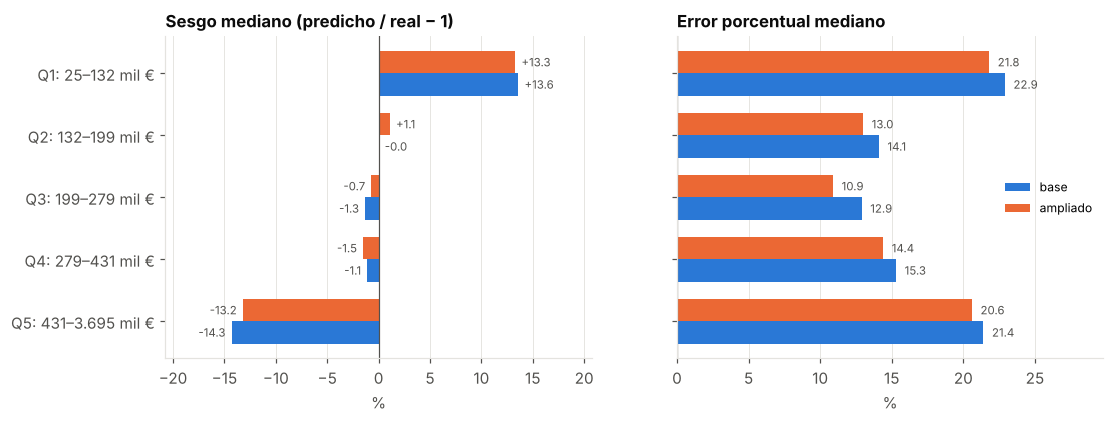

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
y = np.arange(len(tramos))
h = 0.36
for eje, col, titulo in [(ax[0], "sesgo_pct", "Sesgo mediano (predicho / real − 1)"),
                         (ax[1], "MdAPE_pct", "Error porcentual mediano")]:
    for desp, (g, color) in zip((h / 2, -h / 2), [("base", AZUL), ("ampliado", NARANJA)]):
        v = tramos[(g, col)]
        eje.barh(y + desp, v, height=h, color=color, label=g)
        for yi, vi in zip(y + desp, v):
            eje.text(vi + (0.6 if vi >= 0 else -0.6), yi, f"{vi:+.1f}" if col == "sesgo_pct" else f"{vi:.1f}",
                     va="center", ha="left" if vi >= 0 else "right", fontsize=7.5, color=TINTA_2)
    eje.axvline(0, color=TINTA_2, linewidth=0.8)
    eje.set(title=titulo, xlabel="%"); eje.grid(axis="y", visible=False)
lim = tramos.xs("sesgo_pct", axis=1, level=1).abs().max().max() * 1.45
ax[0].set_xlim(-lim, lim); ax[1].set_xlim(0, tramos.xs("MdAPE_pct", axis=1, level=1).max().max() * 1.3)
ax[0].set_yticks(y, tramos.index); ax[0].invert_yaxis()
ax[1].legend(loc="center right", fontsize=8)
guardar(fig, "03_extremos_base_vs_ampliado")

In [8]:
segm = pd.concat({"Tipo": resumen("grupo"), "Localización": resumen("localizacion"),
                  "Provincia": resumen("provincia")})
segm

base                      ampliado  \
                                 viviendas MdAPE_pct sesgo_pct viviendas   
Tipo         Casas                     561      19.0       0.2       561   
             Pisos y otros             807      15.1      -0.5       807   
Localización Capital                   335      15.7      -4.1       335   
             Resto de municipios      1033      16.4       0.6      1033   
Provincia    Almería                   131      15.3      -5.9       131   
             Cádiz                     242      14.9      -0.4       242   
             Córdoba                   147      18.2       1.0       147   
             Granada                   125      13.5      -0.8       125   
             Huelva                    111      17.4      -1.8       111   
             Jaén                      165      19.6      -3.7       165   
             Málaga                    329      16.7       3.6       329   
             Sevilla                   118      16.7      -0.7       118   

                                                      
                                 MdAPE_pct sesgo_pct  
Tipo         Casas                    17.0      -0.9  
             Pisos y otros            14.6       0.7  
Localización Capital                  15.1      -2.5  
             Resto de municipios      15.5       0.7  
Provincia    Almería                  14.6      -1.3  
             Cádiz                    13.8      -0.4  
             Córdoba                  18.3       0.7  
             Granada                  14.7      -2.0  
             Huelva                   13.9      -1.9  
             Jaén                     19.2      -3.7  
             Málaga                   16.3       2.9  
             Sevilla                  16.4       0.3

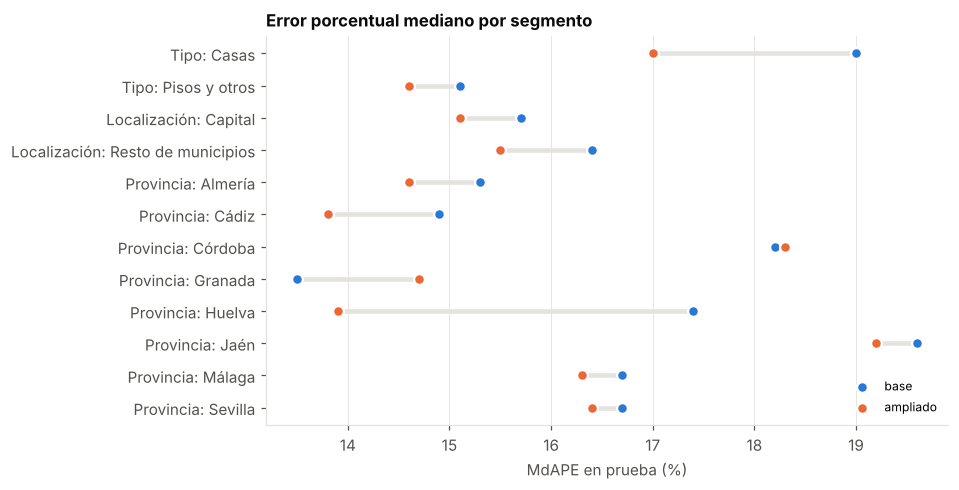

In [9]:
t = segm.iloc[::-1]
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hlines(y, t[("ampliado", "MdAPE_pct")], t[("base", "MdAPE_pct")], color=REJILLA, linewidth=3, zorder=1)
ax.scatter(t[("base", "MdAPE_pct")], y, color=AZUL, s=50, zorder=3, edgecolor="white", linewidth=1.5, label="base")
ax.scatter(t[("ampliado", "MdAPE_pct")], y, color=NARANJA, s=50, zorder=3, edgecolor="white", linewidth=1.5,
           label="ampliado")
ax.set_yticks(y, [f"{g}: {v}" for g, v in t.index]); ax.grid(axis="y", visible=False)
ax.set(title="Error porcentual mediano por segmento", xlabel="MdAPE en prueba (%)")
ax.legend(loc="lower right", fontsize=8)
guardar(fig, "04_segmentos_base_vs_ampliado")

**El error baja en todos los tramos de precio, pero el sesgo de los extremos apenas cambia.**

- La MdAPE mejora entre 0,8 y 2 puntos en cada quintil. La mejora es mayor en los tramos centrales: en Q3 pasa de 12,9 % a 10,9 %.
- El sesgo de los extremos queda casi igual: Q1 pasa de +13,6 % a +13,3 % y Q5 de −14,3 % a −13,2 %.

Es decir, las variables nuevas hacen el modelo más preciso de forma general, pero no corrigen la regresión hacia la media. Ese sesgo es, en gran parte, una propiedad estadística de cualquier predictor imperfecto cuando se agrupa por el **precio real**. Si una vivienda está muy por encima de lo que explican sus características (calidades interiores, reforma de lujo, un precio de salida optimista del vendedor), el modelo no puede saberlo. Al agrupar por precio real, esos casos se concentran en el quintil superior, y los opuestos en el inferior. Reducirlo exigiría información que no está en los campos del anuncio, como las fotografías.

Por segmentos:

- La mejora más clara es en **casas** (19,0 % → 17,0 %), lo que reduce su diferencia con los pisos (15,1 % → 14,6 %).
- También mejora mucho **Huelva** (17,4 % → 13,9 %), provincia con un fuerte contraste entre costa e interior.
- Las provincias de interior apenas cambian: **Córdoba** pasa de 18,2 % a 18,3 % y **Jaén** de 19,6 % a 19,2 %. Es coherente con que la distancia a la costa sea la variable nueva más importante.
- **Granada** empeora (13,5 % → 14,7 %). Con 125 viviendas, la diferencia está dentro de lo esperable por azar.

## 4. Efecto de las variables de texto

Para cada indicador de texto se compara el sesgo mediano del modelo base y del ampliado en las
viviendas de prueba que lo contienen. Si la variable recoge información que antes faltaba, el sesgo
de ese grupo debería acercarse a cero.

In [10]:
limpio = pd.read_csv(RAIZ / "data" / "procesado" / "fotocasa_andalucia_limpio.csv",
                     usecols=["id_anuncio", "titulo", "descripcion"], dtype={"id_anuncio": str})
txt = variables_extra.variables_texto(limpio).assign(id_anuncio=limpio["id_anuncio"])
pt = pb[["id_anuncio", "error_rel"]].rename(columns={"error_rel": "base"}).assign(ampliado=pa["error_rel"].values)
pt = pt.merge(txt, on="id_anuncio", how="left")
filas = []
for v in variables_extra.VARIABLES_TEXTO:
    s = pt[pt[v] == 1]
    filas.append(dict(variable=v.removeprefix("txt_").replace("_", " "), viviendas=len(s),
                      sesgo_base_pct=s["base"].median() * 100, sesgo_ampliado_pct=s["ampliado"].median() * 100))
efecto_txt = pd.DataFrame(filas).set_index("variable").sort_values("sesgo_base_pct")
efecto_txt.round(1)

,viviendas,sesgo_base_pct,sesgo_ampliado_pct
variable,,,
piscina desbordante,10,-28.5,-19.3
lujo,95,-8.7,-0.3
vistas mar,91,-4.2,-1.7
primera linea,50,-3.0,6.1
spa,123,-2.8,2.8
reformado,171,-1.8,-0.9
playa,311,-1.7,0.9
a estrenar,41,-0.3,3.9
inversion,371,1.3,0.7


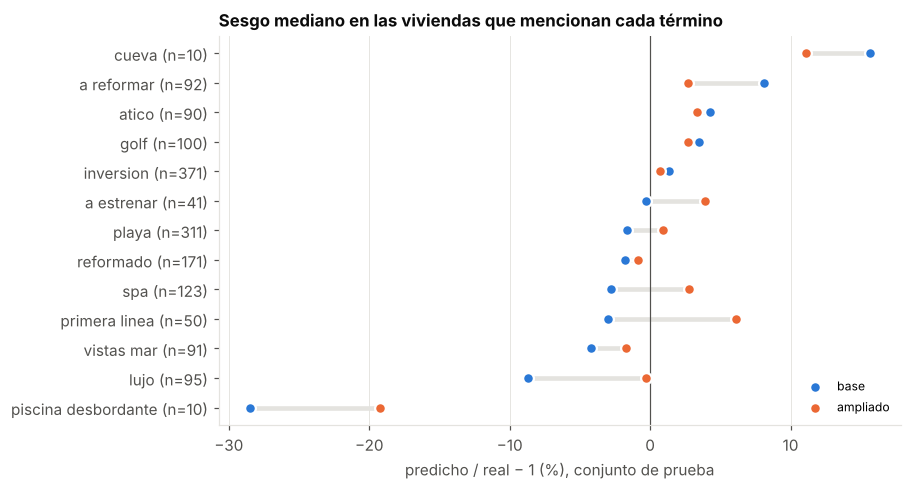

In [11]:
t = efecto_txt[efecto_txt["viviendas"] >= 10]
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hlines(y, t["sesgo_ampliado_pct"], t["sesgo_base_pct"], color=REJILLA, linewidth=3, zorder=1)
ax.scatter(t["sesgo_base_pct"], y, color=AZUL, s=50, zorder=3, edgecolor="white", linewidth=1.5, label="base")
ax.scatter(t["sesgo_ampliado_pct"], y, color=NARANJA, s=50, zorder=3, edgecolor="white", linewidth=1.5,
           label="ampliado")
ax.axvline(0, color=TINTA_2, linewidth=0.8)
ax.set_yticks(y, [f"{i} (n={n})" for i, n in zip(t.index, t["viviendas"])]); ax.grid(axis="y", visible=False)
ax.set(title="Sesgo mediano en las viviendas que mencionan cada término",
       xlabel="predicho / real − 1 (%), conjunto de prueba")
ax.legend(loc="lower right", fontsize=8)
guardar(fig, "05_sesgo_por_termino")

Las variables de texto corrigen el sesgo de los grupos para los que se diseñaron:

- **Lujo** (n = 95): pasa de una infravaloración del 8,7 % a prácticamente cero (−0,3 %).
- **A reformar** (n = 92): la sobrestimación baja de +8,1 % a +2,7 %.
- **Vistas al mar**: el sesgo pasa de −4,2 % a −1,7 %.
- **Viviendas ocupadas** (n = 6): pasa de +22 % a +8 %.
- **Piscina desbordante** (n = 10): pasa de −28 % a −19 %.

En **primera línea** (n = 50), el modelo pasa de infravalorar (−3 %) a sobrestimar (+6 %). Probablemente se suman dos señales que recogen lo mismo, el término de texto y la distancia a la costa casi nula.

Los grupos pequeños (cueva, ocupada, piscina desbordante) tienen muy pocos casos en prueba y deben leerse con cautela.

Los términos se eligieron con los residuos del modelo base sobre el mismo conjunto de entrenamiento con el que luego se hace la validación cruzada. Esto puede hacer la estimación de validación cruzada ligeramente optimista. El conjunto de prueba, que no intervino en la selección, confirma la mejora (MAE −4,3 %).

## 5. Explicabilidad del modelo ampliado (SHAP)

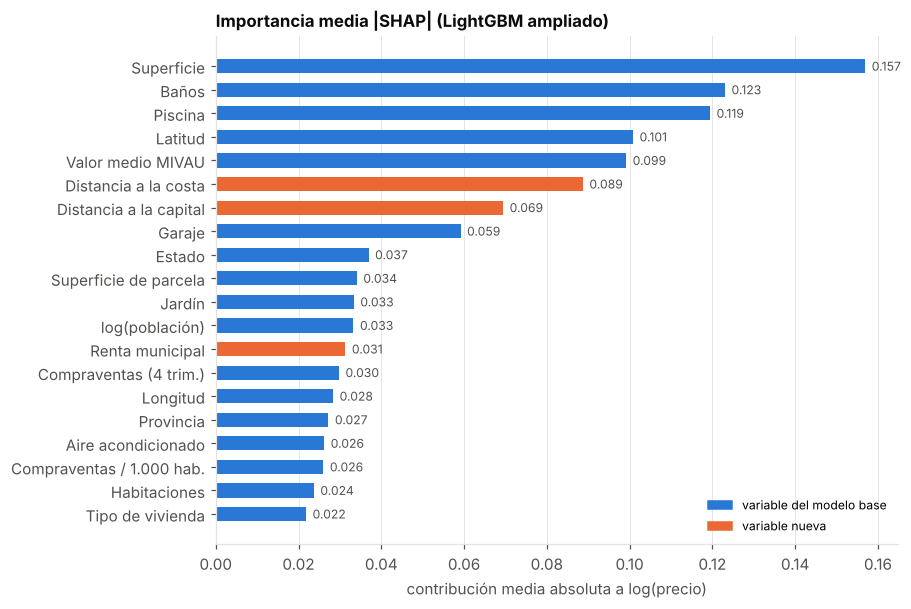

Peso de las variables nuevas en la importancia total: 19.9 %


,% del total
dist_costa_km,6.4
dist_capital_km,5.0
renta_neta_persona,2.3
txt_lujo,1.5
txt_inversion,0.9
txt_primera_linea,0.7
txt_playa,0.5
txt_atico,0.5
txt_a_reformar,0.5
txt_spa,0.5


In [12]:
X_train, X_test, y_train, y_test, ctx = preparar(grupos=GRUPOS)
modelo = joblib.load(RAIZ / "models" / "_".join(GRUPOS) / f"{MEJOR}.joblib")
assert np.allclose(np.exp(modelo.predict(X_test)), pred_amp[f"pred_{MEJOR}"], rtol=1e-6)  # mismo modelo
valores = shap.TreeExplainer(modelo)(X_test)
shap_df = pd.DataFrame(valores.values, columns=X_test.columns)

def variable_original(c):
    if c == "log_superficie":
        return "superficie_m2"
    for pref in ["tipo_vivienda_", "estado_", "orientacion_", "provincia_"]:
        if c.startswith(pref):
            return pref[:-1]
    return c

grupos_col = pd.Series([variable_original(c) for c in X_test.columns], index=X_test.columns)
importancia = shap_df.abs().T.groupby(grupos_col).sum().T.mean().sort_values()
NUEVAS = set(v for g in GRUPOS for v in variables_extra.GRUPOS[g])
NOMBRES_VAR = {
    "superficie_m2": "Superficie", "banos": "Baños", "habitaciones": "Habitaciones", "latitud": "Latitud",
    "longitud": "Longitud", "mivau_valor_medio_ref_eur": "Valor medio MIVAU",
    "mivau_trans_por_1000hab": "Compraventas / 1.000 hab.", "mivau_trans_total_4t": "Compraventas (4 trim.)",
    "log_poblacion": "log(población)", "antiguedad_anos": "Antigüedad", "planta_num": "Planta",
    "superficie_terreno_m2": "Superficie de parcela", "tipo_vivienda": "Tipo de vivienda", "estado": "Estado",
    "orientacion": "Orientación", "provincia": "Provincia", "es_capital": "Capital", "piscina": "Piscina",
    "ascensor": "Ascensor", "terraza": "Terraza", "parking": "Garaje", "jardin": "Jardín",
    "aire_acondicionado": "Aire acondicionado", "trastero": "Trastero", "obra_nueva": "Obra nueva",
    "dist_costa_km": "Distancia a la costa", "dist_capital_km": "Distancia a la capital",
    "renta_neta_persona": "Renta municipal",
}
nombre_var = lambda v: NOMBRES_VAR.get(v, v.replace("txt_", "texto: ").replace("_", " "))

top = importancia.tail(20)
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(top))
ax.barh(y, top.values, color=[NARANJA if v in NUEVAS else AZUL for v in top.index], height=0.6)
for yi, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, yi, f"{v:.3f}", va="center", fontsize=8, color=TINTA_2)
ax.set_yticks(y, [nombre_var(i) for i in top.index]); ax.grid(axis="y", visible=False)
ax.set(title=f"Importancia media |SHAP| ({NOMBRES[MEJOR]} ampliado)",
       xlabel="contribución media absoluta a log(precio)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=NARANJA)],
          labels=["variable del modelo base", "variable nueva"], loc="lower right", fontsize=8)
guardar(fig, "06_importancia_shap_ampliado")
cuota = importancia / importancia.sum() * 100
print(f"Peso de las variables nuevas en la importancia total: {cuota[cuota.index.isin(NUEVAS)].sum():.1f} %")
(cuota.sort_values(ascending=False)[lambda s: s.index.isin(NUEVAS)]).round(1).to_frame("% del total")

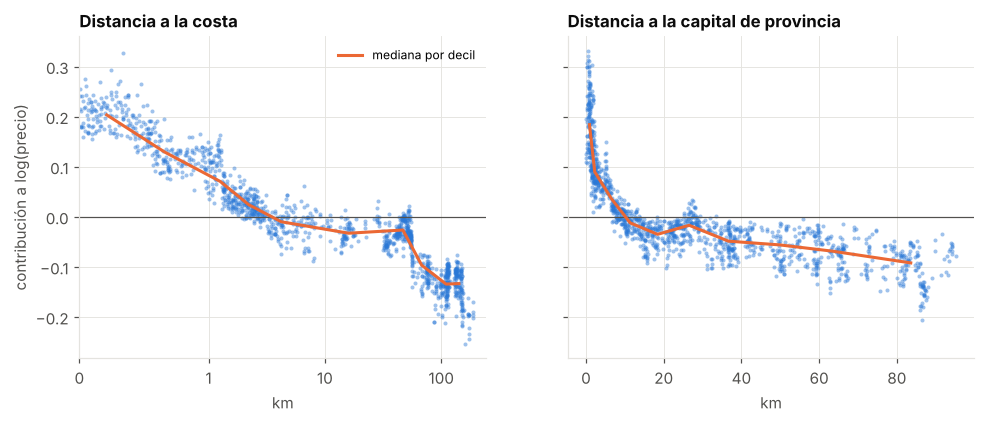

Efecto mediano de la costa a ≤1 km: +18.0%
Efecto mediano de la costa a ~5 km: -1.3%
Efecto mediano de la costa a ~20 km: -2.5%
Efecto mediano de la costa a ~60 km: -3.9%


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for eje, var, titulo in [(ax[0], "dist_costa_km", "Distancia a la costa"),
                         (ax[1], "dist_capital_km", "Distancia a la capital de provincia")]:
    eje.scatter(X_test[var], shap_df[var], s=7, alpha=0.45, color=AZUL, linewidth=0)
    eje.axhline(0, color=TINTA_2, linewidth=0.8)
    eje.set(title=titulo, xlabel="km")
    # efecto mediano por tramo de distancia, para leer la tendencia
    tramos_d = pd.cut(X_test[var], np.quantile(X_test[var].dropna(), np.linspace(0, 1, 11)), include_lowest=True)
    m = pd.DataFrame({"x": X_test[var], "s": shap_df[var]}).groupby(tramos_d, observed=True).median()
    eje.plot(m["x"], m["s"], color=NARANJA, linewidth=2, label="mediana por decil")
ax[0].set_xscale("symlog", linthresh=1); ax[0].set_xlim(0, X_test["dist_costa_km"].max() * 1.3); ax[0].xaxis.set_major_formatter(mticker.ScalarFormatter())
ax[0].set_ylabel("contribución a log(precio)"); ax[0].legend(fontsize=8)
guardar(fig, "07_dependencia_distancias")
for d in (1, 5, 20, 60):
    s = shap_df.loc[X_test["dist_costa_km"] <= d, "dist_costa_km"].median() if d == 1 else \
        shap_df.loc[X_test["dist_costa_km"].between(d * 0.8, d * 1.2), "dist_costa_km"].median()
    print(f"Efecto mediano de la costa a {'≤' if d == 1 else '~'}{d} km: {np.exp(s) - 1:+.1%}")

Las variables nuevas suman el **20 % de la importancia total** del modelo.

- **Distancia a la costa** (6.ª variable más importante, por delante del garaje): estar a menos de 1 km de la costa aporta en torno a un **+18 %** al precio predicho. El efecto se anula hacia los 3–5 km y llega a cerca de un −13 % en el interior, a más de 80 km. Entre los 40 y los 60 km aparece un escalón que no es un efecto propiamente costero: a esa distancia están ciudades como Sevilla o Granada, y la variable actúa en parte como identificador de zona.
- **Distancia a la capital de provincia** (7.ª): las viviendas a 1–2 km del centro de la capital reciben cerca de un +20 %. El efecto es neutro a unos 10 km y negativo de forma suave a partir de ahí, hasta cerca de un −9 % a 80 km.
- **Renta municipal** (13.ª): aunque no mejora la precisión, el modelo la utiliza. Reparte con ella parte de la importancia que antes tenían otras variables municipales, como el valor medio del MIVAU o la población. Es un recordatorio de que la importancia SHAP mide cuánto usa el modelo una variable, no cuánto mejora la predicción.
- **Variables de texto**: tienen importancia media pequeña (la mayor es «lujo», con un 1,5 %), porque afectan a pocas viviendas. Para esas viviendas su efecto es grande, como muestra la sección anterior.

## 6. Conclusiones

1. **El modelo ampliado (LightGBM con texto, geografía y renta) pasa a ser el modelo final.**
   - Error de validación cruzada: −5,4 %.
   - En prueba: R² en logaritmo de 0,863, MdAPE de 15,5 % y MAE de 76.081 €.
   - Retirar la renta no cambia el error (0,2887 frente a 0,2888). Se mantiene por coherencia con los resultados ya calculados; un modelo sin ella sería igual de válido y más sencillo.
2. **Qué ha funcionado.** La distancia a la costa y a la capital, y los indicadores de texto, aportan información que los campos estructurados no tenían: litoral frente a interior, centro frente a periferia, calidad y estado de conservación. Ambos grupos contribuyen por igual y se suman.
3. **Qué no ha funcionado.** La renta municipal es redundante con el contexto municipal que ya tenía el modelo.
4. **Limitación que persiste.** La regresión hacia la media en los extremos de precio (±13 %) apenas se reduce. Se debe a lo que el anuncio no describe: calidades, reformas, vistas concretas, precio de salida del vendedor. Al agrupar por precio real, es una propiedad esperable de cualquier modelo con error.
5. **Trabajo futuro.**
   - Extraer información de las **fotografías** del anuncio (calidad de acabados, estado) con redes convolucionales o modelos de visión preentrenados.
   - Representar la **descripción completa** con *embeddings* de lenguaje en lugar de palabras clave.
   - Usar variables de entorno a escala inferior al municipio: renta por sección censal, distancia a servicios.
   - Usar precios de **transacción** en lugar de precios de oferta, para separar el valor de la vivienda del margen de negociación.